In [1]:
from schedulers import CosineNoiseScheduler, LinearNoiseScheduler
from config import config
from modules import RandomTimeStepSampler

noise_scheduler = CosineNoiseScheduler(config)
alpha, beta = noise_scheduler()
print(noise_scheduler.alpha_bar.shape)

torch.Size([1001])


In [2]:
alpha.shape, beta.shape

(torch.Size([1001]), torch.Size([1001]))

In [3]:
alpha[:10], alpha[-10:]

(tensor([1.0000, 1.0000, 1.0000, 0.9999, 0.9999, 0.9999, 0.9999, 0.9999, 0.9999,
         0.9999]),
 tensor([0.8100, 0.7901, 0.7656, 0.7347, 0.6945, 0.6400, 0.5625, 0.4444, 0.2500,
         0.0010]))

In [4]:
noise_scheduler = LinearNoiseScheduler(config)
alpha_l, beta_l = noise_scheduler()
print(noise_scheduler.alpha_bar.shape)


torch.Size([1001])


In [5]:
alpha_l[-10:]

tensor([0.9802, 0.9802, 0.9801, 0.9801, 0.9801, 0.9801, 0.9801, 0.9800, 0.9800,
        0.9800])

In [6]:
alpha_l[-1]

tensor(0.9800)

In [7]:
from modules import NoiseInjector
cosine_noise_injector = NoiseInjector(config)
config["scheduler"] = "linear"
linear_noise_injector = NoiseInjector(config)

In [8]:
linear_noise_injector, cosine_noise_injector

(NoiseInjector(
   (scheduler): LinearNoiseScheduler()
   (noise_scheduler): LinearNoiseScheduler()
 ),
 NoiseInjector(
   (scheduler): CosineNoiseScheduler()
   (noise_scheduler): CosineNoiseScheduler()
 ))

In [9]:
from utils import load_test_img
from modules import RandomTimeStepSampler
time_step_sampler  =RandomTimeStepSampler(config)
config["test_img_dir"] = "../data/test_images/test_img.png"

In [10]:
x0 = load_test_img()
t = time_step_sampler(batch_size = 1, device = x0.device)

In [11]:
import torch

ts = torch.tensor([100, 200, 300, 400, 500, 600, 700, 800, 900, 1000])
linear_noisy_imgs = []
cosine_noisy_imgs = []

for t in ts:
    linear_noisy_img, linear_eps = linear_noise_injector(x0, t)
    cosine_noisy_img, cosine_eps = cosine_noise_injector(x0, t)

    linear_noisy_imgs.append(linear_noisy_img)
    cosine_noisy_imgs.append(cosine_noisy_img)

In [12]:
import matplotlib.pyplot as plt
def plot_img(imgs, title):
    fig, axes = plt.subplots(
        1, len(ts),
        figsize=(3 * len(ts), 3),
        gridspec_kw={"wspace": 0, "hspace": 0}
    )

    fig.suptitle(title, fontsize=16, fontweight="bold")

    for i, ax in enumerate(axes):
        img = imgs[i].squeeze(0).permute(1, 2, 0).cpu()
        ax.imshow(torch.clip(img, 0, 1).numpy())
        ax.axis("off")

    plt.subplots_adjust(wspace=0, hspace=0)
    plt.show()

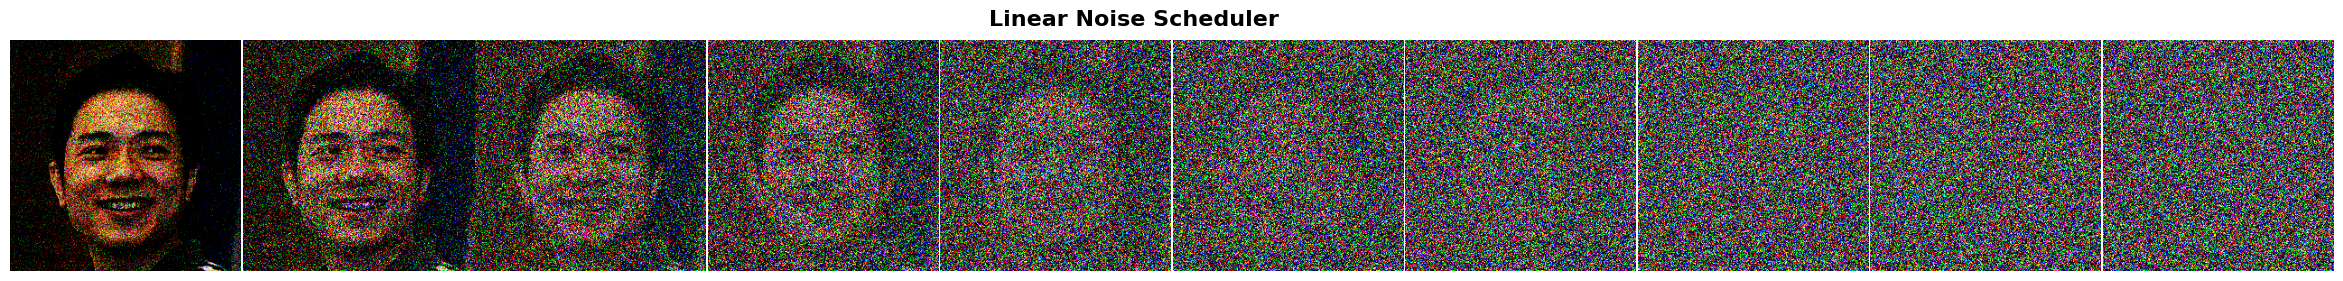

In [13]:
plot_img(linear_noisy_imgs, title="Linear Noise Scheduler")

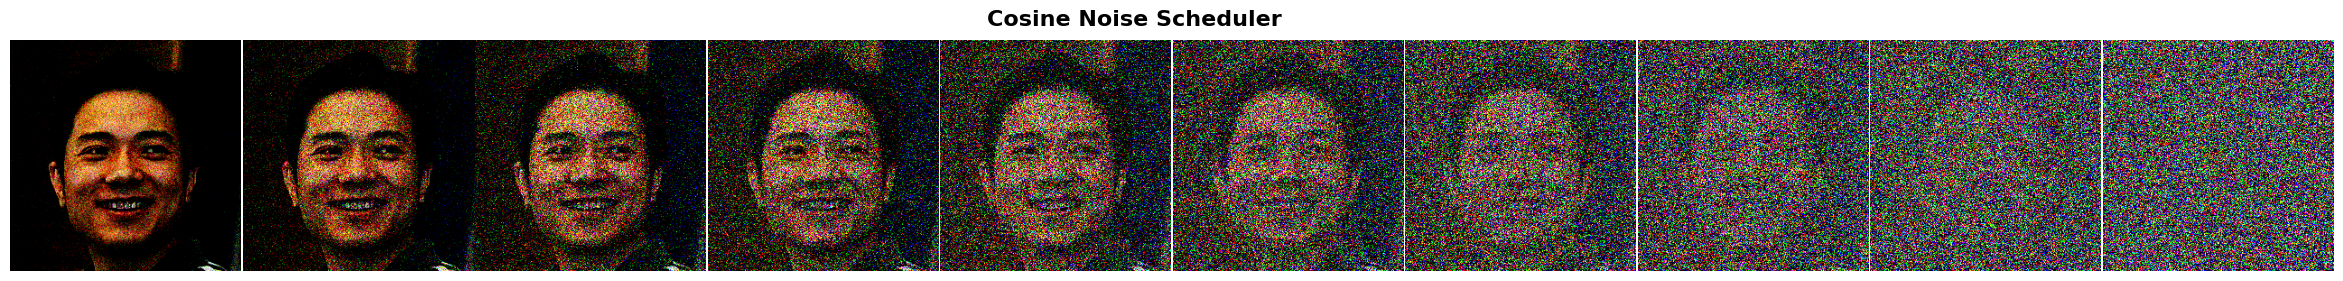

In [14]:
plot_img(cosine_noisy_imgs, title="Cosine Noise Scheduler")